# Escenarios: LiST adverso y extremo, la corrida rápida de 2023 y un generador de depositantes

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 03 de este tema
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- componer un escenario de liquidez a partir de tasas de fuga por segmento con el motor y reconstruir el período de supervivencia de las variantes LiST Adverso y Extremo;
- calibrar una tasa de corrida rápida solo con corridas observadas anteriores a 2023, ver al motor rechazar las filas de 2023 y decir por qué ese rechazo es la guarda de fuga de información del caso;
- correr la grilla de la proporción no asegurada y leer la prueba de monotonía;
- usar un generador de depositantes cuya verdad exacta se conoce para contrastar una estimación de fuga.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cuatro documentos versionados del caso C16 (agregados reales del reporte de llamada de la FDIC del banco que quebró el 2023-03-10, comportamiento y depósitos sintéticos, clase de licencia `mirror-allowed`):

- `list-adverse.json`, `list-extreme.json` y `fast-run.json`: las tres variantes de trayectoria, cada una con sus segmentos, sus series diarias, su período de supervivencia, su evaluación frente a la corrida de marzo de 2023 y sus sensibilidades.
- `models-svb-liquidity.json`: el documento de modelos, con la calibración de la tasa de la corrida rápida sobre las filas de la Tabla A.1 y la configuración, la verdad exacta y la verificación del generador de depositantes.

Un escenario tiene una familia (idiosincrático, de todo el mercado o combinado) y una fase (aguda, de uno a cinco días, o prolongada, hasta seis a doce meses) (BCBS, 2008, Principio 10); el documento dice qué familia y fase toma cada variante. Todos los archivos están en `data/derived/C16/`; los montos están en miles de USD.

In [2]:
# Cargar los cuatro documentos versionados (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
documents = {}
for name in ("list-adverse", "list-extreme", "fast-run", "models-svb-liquidity"):
    documents[name] = json.loads((ROOT / "data" / "derived" / "C16" / f"{name}.json").read_text(encoding="utf-8"))
    print(name, "| calculado con riskvalidation", documents[name]["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

adverse, extreme, fast, models = (documents[k] for k in ("list-adverse", "list-extreme", "fast-run", "models-svb-liquidity"))
rows = {row["variant"]: row for row in adverse["outputs"]["conventions"]["variant_scenarios"]["rows"]}
for variant, row in rows.items():
    print(f"{variant:14s} horizonte (días): {row['horizon_days']:4d}")

list-adverse | calculado con riskvalidation 1.0.0 | instalado 1.0.0
list-extreme | calculado con riskvalidation 1.0.0 | instalado 1.0.0
fast-run | calculado con riskvalidation 1.0.0 | instalado 1.0.0
models-svb-liquidity | calculado con riskvalidation 1.0.0 | instalado 1.0.0
lcr-standard   horizonte (días):   30
list-adverse   horizonte (días):  125
list-extreme   horizonte (días):  125
fast-run       horizonte (días):    5
htm-losses     horizonte (días):  125


## Método

### Paso 1: los conjuntos de parámetros de LiST

El LiST 2019 del BCE fija la tasa diaria de fuga capitalizada de cada clase de vencimiento abierto bajo tres severidades, Base, Adverso y Extremo (BCE, 2019, nota metodológica, Tabla 3.3). El motor las guarda como `list_scenario(severity)`. Una clase que el conjunto no tiene se rechaza, nunca se mapea en silencio, y los choques de LiST son solo idiosincráticos. La celda siguiente imprime las tasas de las clases que usan los segmentos de C16.

In [3]:
# Las tasas diarias de las clases que usan los segmentos del caso, bajo las tres severidades
from riskvalidation.liquidity.scenarios import list_scenario

classes = ("other-retail", "non-operational-non-financial-corporates", "non-operational-other-financial")
print(f"{'clase':44s}{'Base':>12s}{'Adverso':>12s}{'Extremo':>12s}")
for liquidity_class in classes:
    rates = [list_scenario(severity).class_rate(liquidity_class) for severity in ("baseline", "adverse", "extreme")]
    print(f"{liquidity_class:44s}{rates[0]:12.8f}{rates[1]:12.8f}{rates[2]:12.8f}")

try:
    list_scenario("severe")
except ValueError:
    print("una severidad desconocida se rechaza con un ValueError")

clase                                               Base     Adverso     Extremo
other-retail                                  0.00000000  0.00373218  0.00440873
non-operational-non-financial-corporates      0.00000000  0.00688541  0.01065229
non-operational-other-financial               1.00000000  1.00000000  1.00000000
una severidad desconocida se rechaza con un ValueError


### Paso 2: componer un escenario y su escalera

Un escenario asigna a cada segmento una clase del conjunto de parámetros y un saldo inicial, y guarda su trayectoria de tasas diarias en el horizonte: `compose_scenario(family, phase, parameter_set, segments, horizon)`. Las salidas conductuales son $O_s(d) = B_s \prod_{k<d}(1-q_k)\,q_d$ (cuaderno 02). La escalera de una variante suma las salidas contractuales del balance (la financiación garantizada que vence) y resta las entradas, sobre la misma capacidad de contrapeso (cuaderno 03):

$$\mathrm{NLP}(t) = \mathrm{CBC}(t) - \sum_{s \le t} \Bigl(\sum_{\text{segments}} O_{\text{seg}}(s) + O_{\text{contractual}}(s) - I(s)\Bigr)$$

La celda siguiente compone los escenarios Adverso y Extremo a partir de los segmentos de cada documento (clase y saldo inicial), con la familia y la fase de las convenciones versionadas, suma los flujos contractuales del documento, y compara las salidas totales, la NLP y el período de supervivencia con los versionados.

In [4]:
# Componer los escenarios LiST Adverso y Extremo y reconstruir sus escaleras desde los segmentos versionados
from riskvalidation.liquidity.ladder import net_liquidity_position, survival_period
from riskvalidation.liquidity.scenarios import compose_scenario

words = {"idiosyncratic": "idiosincrático", "protracted": "prolongada", "acute": "aguda"}
built = {}
for variant, severity, document in (("list-adverse", "adverse", adverse), ("list-extreme", "extreme", extreme)):
    lad = document["outputs"]["path"]["ladder"]
    row = rows[variant]
    segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
    scenario = compose_scenario(row["scenario_family"], row["phase"], list_scenario(severity), segments, row["horizon_days"])
    contractual = np.sum([c["amounts"] for c in lad["other_outflows"]], axis=0)
    inflows = np.sum([c["amounts"] for c in lad["inflows"]], axis=0)
    total_outflows = scenario.outflows().sum(axis=0) + contractual
    nlp = net_liquidity_position(np.array(lad["cbc_total"]), total_outflows, inflows)
    result = survival_period(nlp)
    built[variant] = (scenario, nlp, result)
    print(variant, "|", words[scenario.family], words[scenario.phase], "|", "segmentos:", len(scenario.segments))
    print("   mismas salidas totales que el documento:", ("sí" if np.allclose(total_outflows, lad["total_outflows"]) else "no"), "| misma NLP:", ("sí" if np.allclose(nlp, lad["nlp"]) else "no"))
    print("   día de supervivencia:", result.day, "| versionado:", document["outputs"]["path"]["survival"]["day"])

print(f"{'segmento':28s}{'saldo inicial (mil millones USD)':>34s}{'tasa Adverso':>18s}{'tasa Extremo':>18s}")
for seg_a, seg_e in zip(built["list-adverse"][0].segments, built["list-extreme"][0].segments):
    print(f"{seg_a.segment_id:28s}{seg_a.opening / 1e6:34.3f}{seg_a.daily_rates[0]:18.8f}{seg_e.daily_rates[0]:18.8f}")

list-adverse | idiosincrático prolongada | segmentos: 3
   mismas salidas totales que el documento: sí | misma NLP: sí
   día de supervivencia: 62 | versionado: 62
list-extreme | idiosincrático prolongada | segmentos: 3
   mismas salidas totales que el documento: sí | misma NLP: sí
   día de supervivencia: 41 | versionado: 41
segmento                      saldo inicial (mil millones USD)      tasa Adverso      tasa Extremo
retail-insured                                           9.990        0.00373218        0.00440873
non-operational-corporate                              151.592        0.00688541        0.01065229
financial                                               13.899        1.00000000        1.00000000


Dos cosas destacan. La severidad Extrema acorta el período de supervivencia (mientras más se avanza en la severidad, antes se vuelve negativa la NLP), y el segmento corporativo no asegurado, 151,6 mil millones de 175,5 mil millones de depósitos, domina ambos escenarios: su tasa es 0,00688541 diaria bajo Adverso y 0,01065229 bajo Extremo. El segmento financiero sale completo el día 1 en ambos.

### Paso 3: la corrida rápida, calibrada antes de 2023

La turbulencia de 2023 "reajustó los supuestos de velocidad" (BCBS, 2023). El producto agrega una variante de corrida rápida cuya tasa no es una tabla de LiST sino que se calibra con corridas observadas: la tasa diaria implícita de cada fila $i$ de la Tabla A.1 es $q_i = 1-(1-F_i)^{1/n_i}$ (cuaderno 02) y la tasa ajustada es un estadístico de esas tasas; la regla de calibración del documento es el máximo (`maximum-implied-daily-rate`, una convención declarada, porque los dosieres no dan un método de calibración). El protocolo sin fuga de información es este: calibrar con las filas anteriores a 2023 y evaluar con las filas de 2023. El motor lo hace cumplir: una llamada marcada `scored=True` rechaza una fila de 2023. La celda siguiente calibra, intenta la llamada rechazada y compara con la calibración versionada. La observación de Silicon Valley Bank (85% en 2 días; Federal Reserve, 2023) entra solo como un ancla rotulada, nunca como un pronóstico.

In [5]:
# Calibrar la tasa de la corrida rápida con las filas anteriores a 2023, probar una fila de 2023, y comparar con la calibración versionada
from riskvalidation.liquidity.runoff import TABLE_A1
from riskvalidation.liquidity.scenarios import anchor_from_observation, fast_run_scenario

pre_2023 = [run for run in TABLE_A1 if run.year < 2023]
fit = fast_run_scenario(pre_2023, "maximum-implied-daily-rate", scored=True)
calibration = models["fit"]["calibration"]

print("filas usadas:", [run.row_id for run in pre_2023])
print("tasas diarias implícitas:", [round(q, 6) for q in fit.implied_rates])
print("tasa ajustada (máximo):", round(fit.daily_rate, 8), "| versionada:", round(calibration["fitted_daily_rate"]["value"], 8), "| igual:", ("sí" if np.isclose(fit.daily_rate, calibration["fitted_daily_rate"]["value"]) else "no"))

try:
    fast_run_scenario(list(TABLE_A1), "maximum-implied-daily-rate", scored=True)
except ValueError:
    print("una llamada marcada como evaluada con una fila de 2023 es rechazada por el motor (ValueError)")

anchor = anchor_from_observation(0.85, 2)
print("ancla: proporción de salida, días, tasa diaria implícita, afirmación de pronóstico:", anchor["outflow_share"], anchor["days"], round(anchor["implied_daily_rate"], 6), ("sí" if anchor["forecast_claim"] else "no"))

filas usadas: ['icesave-2008', 'northern-rock-2007', 'wamu-2008', 'indymac-2008']
tasas diarias implícitas: [0.002971, 0.054258, 0.010481, 0.005938]
tasa ajustada (máximo): 0.05425839 | versionada: 0.05425839 | igual: sí
una llamada marcada como evaluada con una fila de 2023 es rechazada por el motor (ValueError)
ancla: proporción de salida, días, tasa diaria implícita, afirmación de pronóstico: 0.85 2 0.612702 no


El escenario de corrida rápida pone la tasa ajustada en el segmento corporativo no asegurado (la única clase que guarda un conjunto de parámetros `FastRun`, `concentrated-uninsured`) y mantiene las tasas de LiST Adverso en los demás segmentos, en el horizonte agudo de 5 días. La celda siguiente lo compone, reconstruye su escalera como en el paso 2 y compara con el documento versionado; luego imprime la evaluación versionada de la variante frente a las filas de la Tabla A.1 (las filas más allá del horizonte de 5 días no pueden evaluarse) y sus filas de contrastación.

In [6]:
# Componer la corrida rápida (tasa ajustada en el segmento corporativo no asegurado, LiST Adverso en el resto), reconstruir su escalera y leer su evaluación
from riskvalidation.liquidity.scenarios import Scenario

lad = fast["outputs"]["path"]["ladder"]
row = rows["fast-run"]
segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
rest = compose_scenario(row["scenario_family"], row["phase"], list_scenario("adverse"), {k: v for k, v in segments.items() if k != "non-operational-corporate"}, row["horizon_days"])
corporate = compose_scenario(row["scenario_family"], row["phase"], fit, {"non-operational-corporate": ("concentrated-uninsured", segments["non-operational-corporate"][1])}, row["horizon_days"])
by_id = {s.segment_id: s for s in (*rest.segments, *corporate.segments)}
fast_scenario = Scenario(row["scenario_family"], row["phase"], row["horizon_days"], tuple(by_id[k] for k in segments))

contractual = np.sum([c["amounts"] for c in lad["other_outflows"]], axis=0)
inflows = np.sum([c["amounts"] for c in lad["inflows"]], axis=0)
total_outflows = fast_scenario.outflows().sum(axis=0) + contractual
fast_nlp = net_liquidity_position(np.array(lad["cbc_total"]), total_outflows, inflows)
fast_result = survival_period(fast_nlp)

print("mismas salidas totales que el documento:", ("sí" if np.allclose(total_outflows, lad["total_outflows"]) else "no"), "| misma NLP:", ("sí" if np.allclose(fast_nlp, lad["nlp"]) else "no"))
print("NLP de los 5 días (miles de millones de USD):", [round(float(x) / 1e6, 2) for x in fast_nlp], "| sobrevive el horizonte:", ("sí" if fast_result.survives else "no"))
print(f"{'fila de la Tabla A.1':24s}{'rol':>14s}{'observada':>14s}{'modelada':>14s}")
roles = {"calibration": "calibración", "scored": "evaluada"}
for entry in fast["outputs"]["scoring"]["table_a1_scoring"]:
    modelled = "-" if entry["modelled_share"] is None else f"{entry['modelled_share']:.4f}"
    print(f"{entry['row_id']:24s}{roles[entry['role']]:>14s}{entry['observed_share']:14.2f}{modelled:>14s}")
for entry in fast["tests"]:
    if entry["test_id"] == "liq.runoff_adequacy_back_test":
        print("contrastación:", entry["segment"], "| razón:", round(entry["statistic"], 6), "| semáforo:", entry["light"])

mismas salidas totales que el documento: sí | misma NLP: sí
NLP de los 5 días (miles de millones de USD): [13.8, 27.42, 34.3, 27.25, 20.57] | sobrevive el horizonte: sí
fila de la Tabla A.1               rol     observada      modelada
svb-2023                      evaluada          0.85        0.1708
first-republic-2023           evaluada          0.57             -
svb-uk-2023                   evaluada          0.30        0.1263
credit-suisse-2023            evaluada          0.21             -
signature-2023                evaluada          0.20        0.1263
icesave-2008               calibración          0.20             -
northern-rock-2007         calibración          0.20        0.2528
wamu-2008                  calibración          0.10             -
indymac-2008               calibración          0.08             -
contrastación: board-stated-share | razón: 0.200976 | semáforo: red
contrastación: call-report-dep | razón: 0.214124 | semáforo: red


### Paso 4: la grilla de la proporción no asegurada

El riesgo de corrida de un banco sube con la proporción de sus depósitos que nadie asegura (Diamond y Dybvig, 1983, es la teoría; la proporción no asegurada es el motor que el dosier de investigación conserva). `uninsured_share_grid` conserva el total de los dos saldos y mueve una proporción $\sigma$ al no asegurado:

$$\mathrm{uninsured} = (D_{\text{ins}} + D_{\text{unins}})\,\sigma, \qquad \mathrm{insured} = (D_{\text{ins}} + D_{\text{unins}})\,(1-\sigma)$$

Para cada proporción se corre de nuevo la escalera con los nuevos saldos iniciales. El período de supervivencia no debe alargarse al subir la proporción; la prueba `liq.uninsured_share_sensitivity` toma el mayor aumento del período de supervivencia a lo largo de la grilla, en días. La celda siguiente vuelve a correr la escalera en cada proporción de la grilla versionada y compara los días de supervivencia con el documento.

In [7]:
# Recorrer de nuevo la escalera LiST Adverso en cada proporción no asegurada de la grilla versionada, y probar la monotonía
from riskvalidation.liquidity.scenarios import uninsured_share_grid
from riskvalidation.validation.liquidity import uninsured_share_sensitivity

lad = adverse["outputs"]["path"]["ladder"]
row = rows["list-adverse"]
base = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
shares = [entry["share"] for entry in adverse["outputs"]["sensitivities"]["uninsured_share"]]
contractual = np.sum([c["amounts"] for c in lad["other_outflows"]], axis=0)
inflows = np.sum([c["amounts"] for c in lad["inflows"]], axis=0)

days = []
for (insured, uninsured), share in zip(uninsured_share_grid(base["retail-insured"][1], base["non-operational-corporate"][1], shares), shares):
    openings = dict(base)
    openings["retail-insured"] = (base["retail-insured"][0], insured)
    openings["non-operational-corporate"] = (base["non-operational-corporate"][0], uninsured)
    scenario = compose_scenario(row["scenario_family"], row["phase"], list_scenario("adverse"), openings, row["horizon_days"])
    nlp = net_liquidity_position(np.array(lad["cbc_total"]), scenario.outflows().sum(axis=0) + contractual, inflows)
    outcome = survival_period(nlp)
    days.append(None if outcome.survives else outcome.day)

committed_days = [entry["survival"]["day"] for entry in adverse["outputs"]["sensitivities"]["uninsured_share"]]
print("proporciones no aseguradas:", shares)
print("días de supervivencia, reconstruidos:", days)
print("días de supervivencia, versionados:", committed_days, "| iguales:", ("sí" if days == committed_days else "no"))
sensitivity = uninsured_share_sensitivity(shares, days)
committed_sensitivity = next(entry for entry in adverse["tests"] if entry["test_id"] == "liq.uninsured_share_sensitivity")
print("mayor aumento a lo largo de la grilla (días):", sensitivity.statistic, "| semáforo:", sensitivity.light.value, "| fila versionada:", committed_sensitivity["light"])

proporciones no aseguradas: [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]
días de supervivencia, reconstruidos: [77, 75, 73, 71, 69, 68, 66, 64, 63, 61]
días de supervivencia, versionados: [77, 75, 73, 71, 69, 68, 66, 64, 63, 61] | iguales: sí
mayor aumento a lo largo de la grilla (días): 0.0 | semáforo: green | fila versionada: green


### Paso 5: un generador de depositantes con verdad conocida

Una estimación de fuga solo puede probarse contra una verdad conocida. `DepositorGenerator` simula depositantes de varios segmentos mediante una cadena de Markov sistémica de dos estados sobre los días (calma o estrés, una cadena compartida por todos los depositantes); un depositante aún depositado el día $d$ retira con el hazard $h_{\text{calma}}$ o $h_{\text{estrés}}$ del estado de ese día. Como el modelo es pequeño, su verdad es exacta: con $u_d$ el vector fila de probabilidades de seguir depositado en cada estado, $P$ la matriz de transición entre los estados y $\odot$ el producto elemento a elemento,

$$u_1 = (1 - h_{\text{calm}},\; 0), \qquad u_{d+1} = (u_d P) \odot (1 - h_{\text{calm}},\; 1 - h_{\text{stress}}), \qquad F_{\text{truth}}(n) = 1 - \textstyle\sum u_n$$

La ley de transición del estado de estrés (una probabilidad diaria de entrada de 0,01 y una de salida de 0,05) no tiene fuente en los dosieres: es una convención del motor, declarada como tal (UNVERIFIED). Los segmentos, proporciones y hazards vienen del documento de modelos, que calibró el hazard de estrés del segmento corporativo con la tasa de la corrida rápida. La celda siguiente reconstruye el generador desde la configuración versionada, calcula su verdad exacta y la compara con la versionada.

In [8]:
# Reconstruir el generador desde la configuración versionada y comparar su verdad exacta con la verdad versionada
from riskvalidation.liquidity.deposits import DepositorConfig, DepositorGenerator, DepositorSegment

generator_doc = models["fit"]["generator"]
config = generator_doc["config"]
# una sola cadena de estrés es compartida por todos los depositantes (engine-liquidity-api 2.0.0): sus dos probabilidades pertenecen a la configuración y el documento las repite en cada segmento
chain = {(s["p_enter_stress"], s["p_exit_stress"]) for s in config["segments"]}
assert len(chain) == 1, "las filas de segmento no coinciden en la cadena de estrés compartida"
p_enter, p_exit = chain.pop()
generator = DepositorGenerator(DepositorConfig(
    tuple(DepositorSegment(s["segment"], s["share_of_deposits"], s["calm_daily_hazard"], s["stress_daily_hazard"]) for s in config["segments"]),
    config["n_depositors"], config["horizon_days"], p_enter, p_exit))
truth = generator.truth()["outflow_rate"]

print("depositantes por segmento y horizonte:", config["n_depositors"], config["horizon_days"])
for entry in generator_doc["truth"]:
    exact = truth[entry["segment"]][entry["horizon_days"] - 1]
    print(f"{entry['segment']:28s} día {entry['horizon_days']:4d} | verdad exacta {exact:.6f} | versionada {entry['true_outflow_rate']:.6f}")
print("misma verdad que el documento:", ("sí" if all(np.isclose(truth[e["segment"]][e["horizon_days"] - 1], e["true_outflow_rate"]) for e in generator_doc["truth"]) else "no"))

depositantes por segmento y horizonte: 1000 125
retail-insured               día    2 | verdad exacta 0.000037 | versionada 0.000037
retail-insured               día    5 | verdad exacta 0.000350 | versionada 0.000350
retail-insured               día   30 | verdad exacta 0.009646 | versionada 0.009646
retail-insured               día  125 | verdad exacta 0.062623 | versionada 0.062623
non-operational-corporate    día    2 | verdad exacta 0.000543 | versionada 0.000543
non-operational-corporate    día    5 | verdad exacta 0.004852 | versionada 0.004852
non-operational-corporate    día   30 | verdad exacta 0.100707 | versionada 0.100707
non-operational-corporate    día  125 | verdad exacta 0.445510 | versionada 0.445510
financial                    día    2 | verdad exacta 0.010000 | versionada 0.010000
financial                    día    5 | verdad exacta 0.039404 | versionada 0.039404
financial                    día   30 | verdad exacta 0.252828 | versionada 0.252828
financial        

Ahora la contrastación. La estimación es la proporción media de salida acumulada de una muestra con semilla de corridas simuladas, en los horizontes del documento (2, 5, 30 y 125 días); su error estándar de Monte Carlo es la desviación estándar sobre la raíz del número de simulaciones. La prueba `liq.runoff_vs_generator_truth` toma la mayor distancia a la verdad en errores estándar: verde hasta 2, ámbar hasta 3, rojo por encima (compuertas internas del producto). El documento versionó una verificación más grande (20.000 simulaciones); esta celda usa 2.000, que toma una fracción de segundo, e imprime ambas.

In [9]:
# Contrastar la salida simulada con la verdad exacta del generador
from riskvalidation.validation.liquidity import runoff_vs_generator_truth

draws = 2000
rng = np.random.default_rng(42)
samples = {key: np.empty((draws, config["horizon_days"])) for key in truth}
for i in range(draws):
    for key, path in generator.draw(rng)["outflow_rate"].items():
        samples[key][i] = path

horizons = (2, 5, 30, 125)
estimated = np.array([samples[k][:, h - 1].mean() for k in truth for h in horizons])
exact_values = np.array([truth[k][h - 1] for k in truth for h in horizons])
standard_errors = np.array([samples[k][:, h - 1].std(ddof=1) / np.sqrt(draws) for k in truth for h in horizons])

check = runoff_vs_generator_truth(estimated, exact_values, standard_errors)
committed_check = next(entry for entry in fast["tests"] if entry["test_id"] == "liq.runoff_vs_generator_truth")
verification = generator_doc["verification"]
print("simulaciones:", draws, "| comprobaciones:", check.n)
print("mayor distancia en errores estándar:", round(check.statistic, 4), "| semáforo:", check.light.value)
print("fila versionada (20000 simulaciones):", round(committed_check["statistic"], 4), committed_check["light"], "| calculada con", fast["provenance"]["riskvalidation_version"])
print("verificación versionada: simulaciones, mayor error, error estándar, dentro del error:", verification["n_draws"], round(verification["max_abs_error"], 6), round(verification["mc_standard_error"], 6), ("sí" if verification["within_error"] else "no"))

simulaciones: 2000 | comprobaciones: 12
mayor distancia en errores estándar: 1.3558 | semáforo: green
fila versionada (20000 simulaciones): 0.5369 green | calculada con 1.0.0
verificación versionada: simulaciones, mayor error, error estándar, dentro del error: 20000 0.00026 0.000484 sí


La última celda dibuja las dos vistas. A la izquierda, la NLP de las tres variantes: las trayectorias Adversa y Extrema en 125 días con sus días de supervivencia, y los cinco días de la corrida rápida en el mismo eje. A la derecha, la verdad exacta del segmento corporativo del generador con las medias simuladas en los cuatro horizontes y sus barras de dos errores estándar.

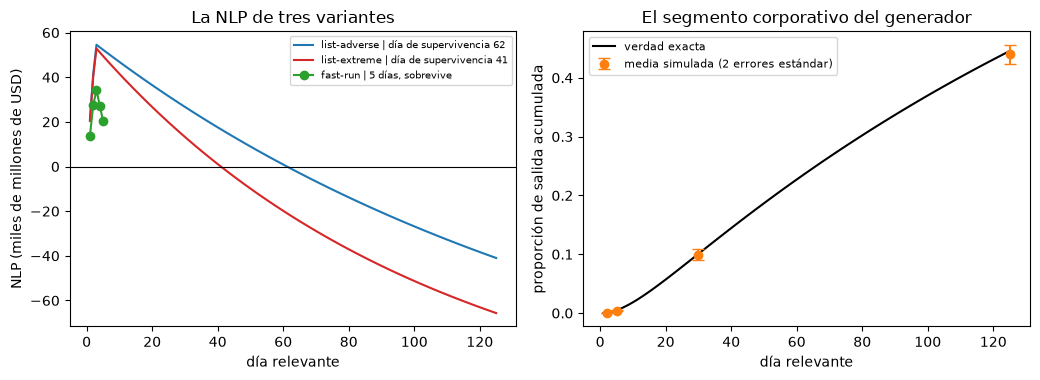

In [10]:
# Dibujar la NLP de las tres variantes y la verdad del generador contra sus medias simuladas
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.9))

for variant, color in (("list-adverse", "tab:blue"), ("list-extreme", "tab:red")):
    nlp_path, result = built[variant][1], built[variant][2]
    left.plot(np.arange(1, len(nlp_path) + 1), nlp_path / 1e6, color=color, label=f"{variant} | día de supervivencia {result.day}")
left.plot(np.arange(1, len(fast_nlp) + 1), fast_nlp / 1e6, color="tab:green", marker="o", label="fast-run | 5 días, sobrevive")
left.axhline(0, color="black", linewidth=0.8)
left.set_xlabel("día relevante")
left.set_ylabel("NLP (miles de millones de USD)")
left.set_title("La NLP de tres variantes")
left.legend(fontsize=7)

key = "non-operational-corporate"
right.plot(np.arange(1, 126), truth[key], color="black", label="verdad exacta")
position = [horizons.index(h) + list(truth).index(key) * len(horizons) for h in horizons]
right.errorbar(horizons, estimated[position], yerr=2 * standard_errors[position], fmt="o", color="tab:orange", capsize=4, label="media simulada (2 errores estándar)")
right.set_xlabel("día relevante")
right.set_ylabel("proporción de salida acumulada")
right.set_title("El segmento corporativo del generador")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **Composición.** Componer los segmentos con el motor reconstruye exactamente ambas escaleras: bajo LiST Adverso la NLP se vuelve negativa el día 62 y bajo Extremo el día 41, como en los documentos. El segmento corporativo no asegurado (151,592 mil millones de USD, una tasa diaria de 0,00688541 bajo Adverso y 0,01065229 bajo Extremo) domina a ambos, y el segmento financiero (13,899 mil millones) sale completo el día 1.
- **La corrida rápida.** La tasa ajustada con las cuatro filas anteriores a 2023 es 0,05425839 (Northern Rock, 20% en 4 días), igual a la calibración versionada, y el motor rechaza una fila de 2023 en una llamada evaluada. Con esa tasa la escalera de 5 días nunca se vuelve negativa (la NLP queda entre 13,80 y 34,30 mil millones, su valor más bajo el día 1), así que sobrevive su horizonte. Sin embargo modela 0,1708 de la base de depósitos en los dos días en que SVB perdió 0,85, y 0,1263 en el único día en que SVB UK perdió 0,30 y Signature 0,20: las razones de la contrastación son 0,200976 y 0,214124, rojo. Calibrada solo con lo ocurrido antes de 2023, incluso la tasa más rápida queda muy corta frente a la corrida con la que se evalúa.
- **La proporción no asegurada.** En las diez proporciones de 0,5 a 0,95 el período de supervivencia cae de 77 a 61 días, los días reconstruidos son iguales a los versionados, y la prueba de monotonía es verde con un aumento máximo de 0,0 días.
- **El generador.** La verdad exacta del generador se reproduce para los tres segmentos en los cuatro horizontes (para el segmento corporativo 0,000543, 0,004852, 0,100707 y 0,445510 a 2, 5, 30 y 125 días). Con 2.000 simulaciones con semilla la mayor distancia a la verdad es 1,3558 errores estándar, verde; la verificación versionada de 20.000 simulaciones tiene un error máximo de 0,00026 frente a un error estándar de 0,000484, y su fila de prueba versionada marca 0,5369. La comprobación vale lo que vale el generador: la ley de estrés es una convención, así que prueba la aritmética de un estimador frente a un mecanismo conocido, no el mecanismo frente a la realidad.

Lo que este cuaderno no muestra: el multiplicador de la fuga con el que el período de supervivencia cae a una meta (cuaderno 06), ni la comparación de las fugas suave y rápida como pregunta de estado del arte (cuaderno 07). Todo período de supervivencia pertenece a un comportamiento sintético sobre agregados reales.

## Resumen

- Un escenario es una familia, una fase y, por segmento, una clase y un saldo inicial; el motor compone las tasas diarias y las salidas, y la escalera del documento se reconstruye exactamente.
- La tasa de la corrida rápida se calibra solo con las filas anteriores a 2023, y el motor rechaza una fila de 2023 en una llamada evaluada: la división de calibración es una regla del código, no una promesa.
- El período de supervivencia es no creciente en la proporción no asegurada y en la severidad, y las pruebas verifican ambas cosas.
- Un generador con verdad exacta convierte una estimación de fuga en una afirmación contrastable, en errores estándar de Monte Carlo.

**Qué probar a continuación.** Cambia la semilla o el número de simulaciones y mira cómo se mueve la mayor distancia a la verdad; luego sigue con el cuaderno 05.

## Referencias

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06), Table 3.3. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2008), Principles for sound liquidity risk management and supervision, Principle 10. https://www.bis.org/publ/bcbs144.htm
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm
- Federal Reserve Board (2023-04-28), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- Diamond, D. W. and Dybvig, P. H. (1983), Bank runs, deposit insurance, and liquidity, Journal of Political Economy 91(3). https://doi.org/10.1086/261155